# Week 1 · Task 4 — Pick the right chart, five times

Data: `mpg.csv` — 398 cars, 1970–1982. Columns: `mpg, cylinders, displacement, horsepower, weight, acceleration, model_year, origin, name`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt          # only plt.subplots() is used; every chart is drawn with methods on ax
from matplotlib.ticker import FuncFormatter
from pathlib import Path

DATA = Path(r"C:\Users\Nas Graphy\Downloads\Data-Visualization\Week 1\mpg.csv")                       # folder made by download_assignment_data.py
GREY, DARK = "#bbbbbb", "#444444"
COL = {"blue": "#0072B2", "orange": "#E69F00", "green": "#009E73", "pink": "#CC79A7", "red": "#D55E00", "sky": "#56B4E9"}
mpl.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

def note(fig, text, y=-0.03):
    # one-line footnote: sample size and any excluded rows are declared on the figure itself
    fig.text(0.01, y, text, fontsize=8, ha="left")

In [2]:
mpg = pd.read_csv(r"C:\Users\Nas Graphy\Downloads\Data-Visualization\Week 1\mpg.csv")
mpg["origin"] = mpg["origin"].str.lower()
mpg["year"] = 1900 + mpg["model_year"]                       # 70 -> 1970
N = len(mpg)
print(mpg.shape); display(mpg.isna().sum().to_frame("missing").T)

(398, 10)


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name,year
missing,0,0,0,6,0,0,0,0,0,0


**Missing values.** Only `horsepower` has gaps (6 cars). None of the five questions uses horsepower (they use `mpg`, `year`, `origin`, `weight` and `cylinders`, which are complete), so **all 398 cars are used in every chart** and nothing is dropped or filled in. This is stated on each chart.

Chart types used: line, box plot, scatter, bar, and a two-panel comparison — five different answers for five different questions.

## Q1. Did cars get more fuel-efficient between 1970 and 1982?

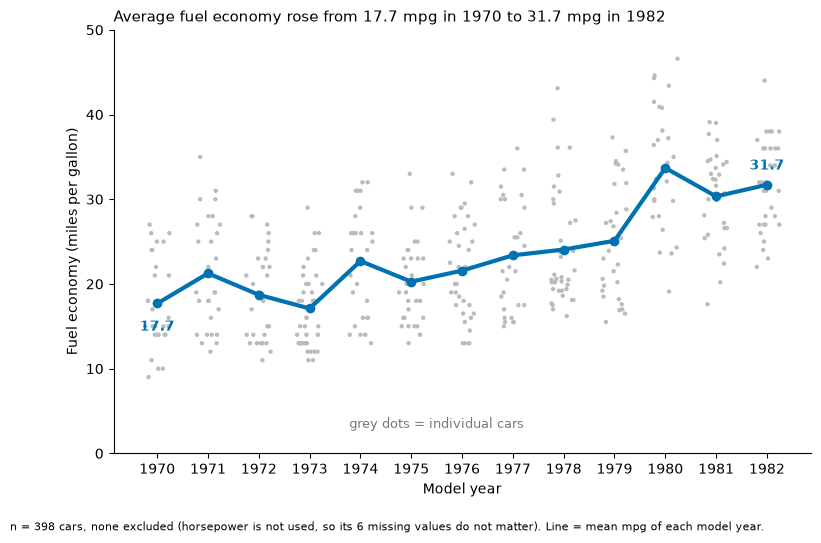

In [3]:
by_year = mpg.groupby("year")["mpg"].mean()
rng = np.random.default_rng(1)
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.scatter(mpg["year"] + rng.uniform(-0.25, 0.25, N), mpg["mpg"], s=10, color=GREY, edgecolors="none", zorder=1)
ax.plot(by_year.index, by_year.values, color=COL["blue"], lw=3, marker="o", zorder=3)
ax.text(1970, by_year.iloc[0] - 3.2, f"{by_year.iloc[0]:.1f}", color=COL["blue"], fontweight="bold", ha="center")
ax.text(1982, by_year.iloc[-1] + 1.8, f"{by_year.iloc[-1]:.1f}", color=COL["blue"], fontweight="bold", ha="center")
ax.text(1975.5, 3, "grey dots = individual cars", color="#777777", fontsize=9, ha="center")
ax.set_xticks(range(1970, 1983)); ax.set_ylim(0, 50)
ax.set_xlabel("Model year"); ax.set_ylabel("Fuel economy (miles per gallon)")
ax.set_title(f"Average fuel economy rose from {by_year.iloc[0]:.1f} mpg in 1970 to {by_year.iloc[-1]:.1f} mpg in 1982", loc="left", fontsize=11)
note(fig, f"n = {N} cars, none excluded (horsepower is not used, so its 6 missing values do not matter). Line = mean mpg of each model year.")
fig.savefig("w1_task4_q1.png", dpi=200, bbox_inches="tight")

**Why a line chart.** Time is ordered and continuous, and the question is about *change*, so a line connecting yearly averages is the natural encoding (the slope is the answer). The grey dots show the 398 individual cars so the reader can see that the average summarises a wide spread, and the line is the only coloured element.

## Q2. Do American, European and Japanese cars differ in fuel efficiency?

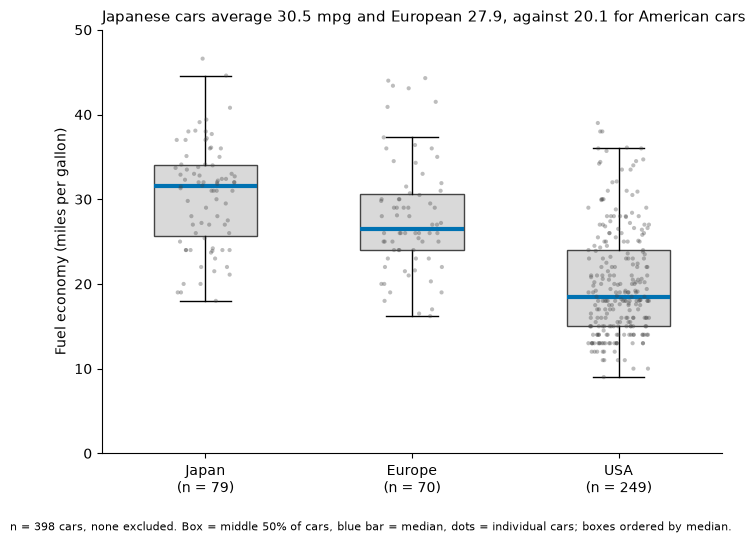

In [4]:
order = mpg.groupby("origin")["mpg"].median().sort_values(ascending=False).index.tolist()
nice = {"usa": "USA", "europe": "Europe", "japan": "Japan"}
data = [mpg.loc[mpg["origin"] == o, "mpg"].values for o in order]
fig, ax = plt.subplots(figsize=(8, 5.5))
bp = ax.boxplot(data, widths=0.5, patch_artist=True, showfliers=False)
for b in bp["boxes"]: b.set(facecolor="#d9d9d9", edgecolor=DARK)
for m_ in bp["medians"]: m_.set(color=COL["blue"], lw=3)
rng = np.random.default_rng(2)
for i, d in enumerate(data, start=1):
    ax.scatter(i + rng.uniform(-0.15, 0.15, len(d)), d, s=9, color=DARK, alpha=0.35, edgecolors="none", zorder=3)
ax.set_xticks(range(1, len(order) + 1)); ax.set_xticklabels([f"{nice[o]}\n(n = {len(d)})" for o, d in zip(order, data)])
ax.set_ylim(0, 50); ax.set_ylabel("Fuel economy (miles per gallon)")
means = mpg.groupby("origin")["mpg"].mean()
ax.set_title(f"Japanese cars average {means['japan']:.1f} mpg and European {means['europe']:.1f}, against {means['usa']:.1f} for American cars", loc="left", fontsize=11)
note(fig, f"n = {N} cars, none excluded. Box = middle 50% of cars, blue bar = median, dots = individual cars; boxes ordered by median.")
fig.savefig("w1_task4_q2.png", dpi=200, bbox_inches="tight")

**Why a box plot with dots.** I am comparing the *distribution* of one numeric variable across three categories. Bars of averages would hide the spread and the overlap between groups; a box plot shows the median and the middle half of each group side by side, and the dots show every car and the group size. Groups are ordered by median, which makes the ranking readable, and one colour is used because the categories are already named on the axis.

## Q3. What is the relationship between weight and fuel efficiency?

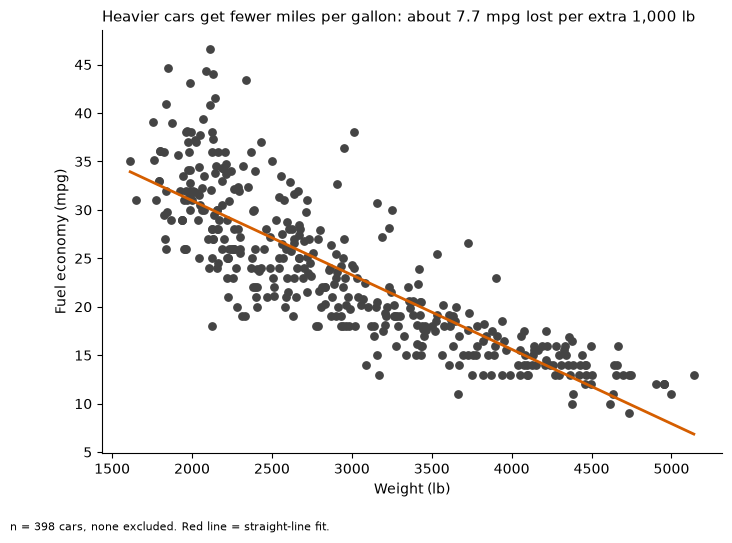

In [5]:
lin = np.polyfit(mpg["weight"], mpg["mpg"], 1)
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.scatter(mpg["weight"], mpg["mpg"], s=28, color=DARK)
xs = np.array([mpg["weight"].min(), mpg["weight"].max()])
ax.plot(xs, np.polyval(lin, xs), color=COL["red"], lw=2)
ax.set_xlabel("Weight (lb)"); ax.set_ylabel("Fuel economy (mpg)")
ax.set_title(f"Heavier cars get fewer miles per gallon: about {abs(lin[0]) * 1000:.1f} mpg lost per extra 1,000 lb", loc="left", fontsize=11)
note(fig, f"n = {N} cars, none excluded. Red line = straight-line fit.")
fig.savefig("w1_task4_q3_v1.png", dpi=200, bbox_inches="tight")

**Why a scatter plot.** Two numeric variables and a "relationship" question: a scatter plot shows each car and the trend, and the fitted line gives the answer in one number. (This is my first version; I judge it the weakest chart in the set and redraw it at the end.)

## Q4. How is the number of cylinders distributed across the fleet?

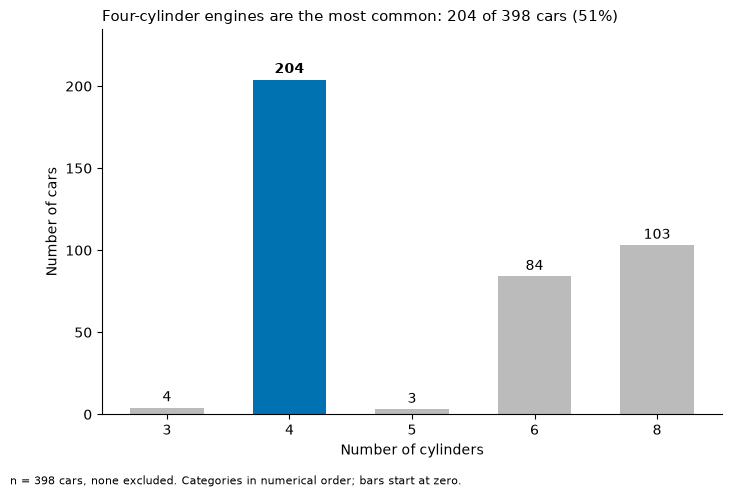

In [6]:
cyl = mpg["cylinders"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(8, 5))
cols = [COL["blue"] if c == cyl.idxmax() else GREY for c in cyl.index]
ax.bar([str(c) for c in cyl.index], cyl.values, color=cols, width=0.6)
for i, v in enumerate(cyl.values):
    ax.text(i, v + 4, f"{v}", ha="center", fontweight="bold" if v == cyl.max() else "normal")
ax.set_ylim(0, cyl.max() * 1.15)                               # bars start at zero
ax.set_xlabel("Number of cylinders"); ax.set_ylabel("Number of cars")
ax.set_title(f"Four-cylinder engines are the most common: {cyl.max()} of {N} cars ({cyl.max() / N:.0%})", loc="left", fontsize=11)
note(fig, f"n = {N} cars, none excluded. Categories in numerical order; bars start at zero.")
fig.savefig("w1_task4_q4.png", dpi=200, bbox_inches="tight")

**Why a bar chart (and not a pie).** Cylinders take only a few discrete values, and the question is "how many cars in each?", so a bar chart of counts is right: bar length from zero is read accurately, and the categories sit in their natural numeric order. A pie would need five slices (3, 4, 5, 6, 8 cylinders), two of them almost invisible (4 and 3 cars), which is exactly what the marking guide penalises.
Only the biggest bar is coloured, because it is the one the title is about.

## Q5. Is the improvement in Q1 explained by Q3? (did cars get lighter?)

mean mpg gain 1970->1982: 14.0 | weight change alone predicts: 6.1 | gain at the same weight (late vs early): 5.9


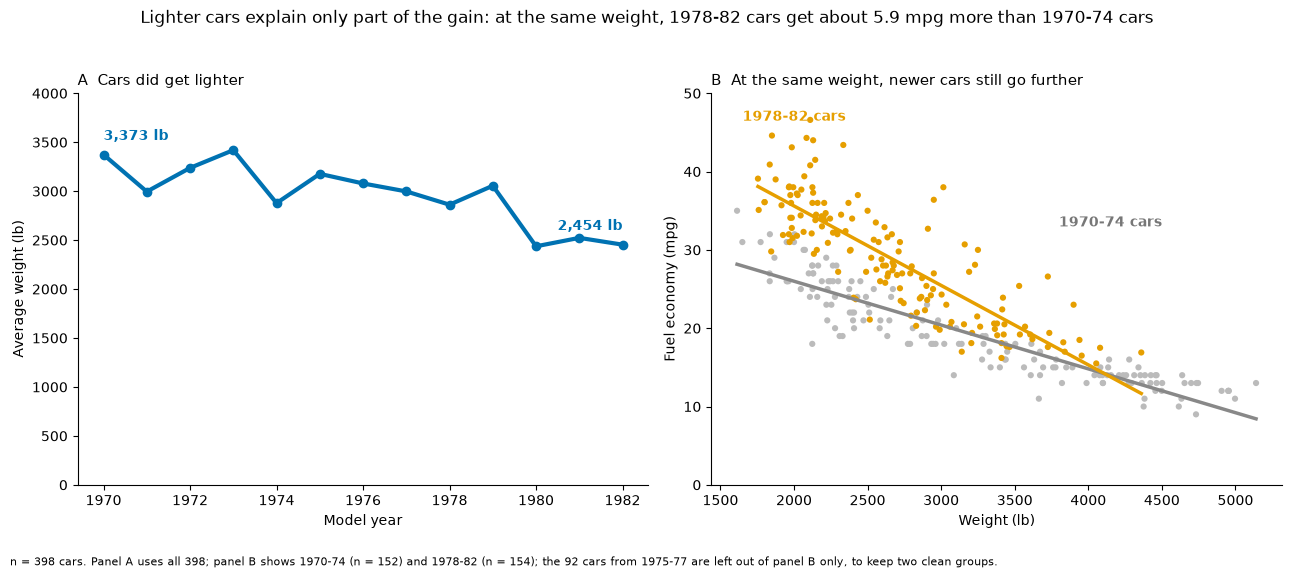

In [7]:
wt_year = mpg.groupby("year")["weight"].mean()
early = mpg[mpg["model_year"] <= 74]; late = mpg[mpg["model_year"] >= 78]
mid_n = N - len(early) - len(late)
# gain in mpg at the SAME weight: regress mpg on weight plus a late-period indicator
d = pd.concat([early.assign(late=0), late.assign(late=1)])
X = np.c_[np.ones(len(d)), d["weight"], d["late"]]
beta = np.linalg.lstsq(X, d["mpg"], rcond=None)[0]
same_weight_gain = beta[2]
# how much of the 1970->1982 gain would the weight change alone predict?
X2 = np.c_[np.ones(N), mpg["weight"], mpg["model_year"]]
b2 = np.linalg.lstsq(X2, mpg["mpg"], rcond=None)[0]
total_gain = by_year.iloc[-1] - by_year.iloc[0]
weight_part = b2[1] * (wt_year.iloc[-1] - wt_year.iloc[0])
print(f"mean mpg gain 1970->1982: {total_gain:.1f} | weight change alone predicts: {weight_part:.1f} | gain at the same weight (late vs early): {same_weight_gain:.1f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
ax = axes[0]
ax.plot(wt_year.index, wt_year.values, color=COL["blue"], lw=3, marker="o")
ax.text(1970, wt_year.iloc[0] + 150, f"{wt_year.iloc[0]:,.0f} lb", color=COL["blue"], ha="left", fontweight="bold")
ax.text(1982, wt_year.iloc[-1] + 150, f"{wt_year.iloc[-1]:,.0f} lb", color=COL["blue"], ha="right", fontweight="bold")
ax.set_ylim(0, 4000); ax.set_xticks(range(1970, 1983, 2))
ax.set_xlabel("Model year"); ax.set_ylabel("Average weight (lb)")
ax.set_title("A  Cars did get lighter", loc="left", fontsize=11)
ax = axes[1]
ax.scatter(early["weight"], early["mpg"], s=20, color=GREY, edgecolors="none")
ax.scatter(late["weight"], late["mpg"], s=20, color=COL["orange"], edgecolors="none")
for dd, colr, lab, xl in [(early, "#888888", "1970-74 cars", 4150), (late, COL["orange"], "1978-82 cars", 2050)]:
    f = np.polyfit(dd["weight"], dd["mpg"], 1); xs = np.array([dd["weight"].min(), dd["weight"].max()])
    ax.plot(xs, np.polyval(f, xs), color=colr, lw=2.5)
ax.text(4150, 33, "1970-74 cars", color="#777777", fontweight="bold", ha="center")
ax.text(2000, 46.5, "1978-82 cars", color=COL["orange"], fontweight="bold", ha="center")
ax.set_xlabel("Weight (lb)"); ax.set_ylabel("Fuel economy (mpg)"); ax.set_ylim(0, 50)
ax.set_title("B  At the same weight, newer cars still go further", loc="left", fontsize=11)
fig.suptitle(f"Lighter cars explain only part of the gain: at the same weight, 1978-82 cars get about {same_weight_gain:.1f} mpg more than 1970-74 cars", fontsize=12)
note(fig, f"n = {N} cars. Panel A uses all {N}; panel B shows 1970-74 (n = {len(early)}) and 1978-82 (n = {len(late)}); the {mid_n} cars from 1975-77 are left out of panel B only, to keep two clean groups.")
fig.tight_layout(rect=(0, 0.01, 1, 0.95))
fig.savefig("w1_task4_q5.png", dpi=200, bbox_inches="tight")

**Why two panels.** The question has two parts: *did cars get lighter?* (a time trend, so a line chart, panel A) and *does weight explain the mpg gain?* (a comparison of two groups on the weight–mpg relationship, so a scatter plot with one fitted line per period, panel B). I did **not** put weight and mpg on one chart with two y-axes (a dual axis would be an automatic deduction); two separate panels with their own axes say it honestly.

**Answer.** Partly. Cars did get lighter (panel A), and because lighter cars use less fuel, that accounts for a good share (roughly 6 of the roughly 14 mpg gained, from the regression printed above). But in panel B the newer cars' fitted line sits clearly above the older cars' line across most of the weight range (the two lines only meet for the heaviest cars, above about 4,200 lb): for the same weight the later cars get several more mpg, so weight alone does not explain the improvement (engine and efficiency improvements must account for the rest). This is not proof of cause, since this is observational data, but it is a clear sign that Q3 is only part of the story.

## The weakest chart, redrawn: Q3

**Which one is weakest and why.** My Q3 scatter. Three problems: (1) 398 opaque dots overlap heavily in the 2,000–3,000 lb range, so you cannot tell how dense the points are; (2) the straight line is the wrong shape — fuel economy falls very steeply for light cars and flattens for heavy ones, so the line is above the points at both ends and below them in the middle; (3) the title gives one average slope that is true nowhere in particular.

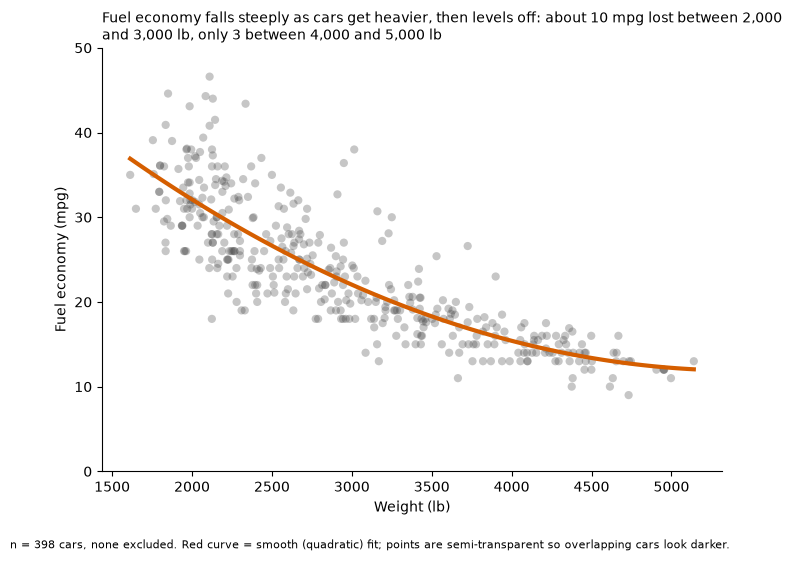

In [8]:
quad = np.polyfit(mpg["weight"], mpg["mpg"], 2)
f = lambda w: np.polyval(quad, w)
drop_light, drop_heavy = f(2000) - f(3000), f(4000) - f(5000)
xs = np.linspace(mpg["weight"].min(), mpg["weight"].max(), 100)

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.scatter(mpg["weight"], mpg["mpg"], s=35, color=DARK, alpha=0.3, edgecolors="none")           # transparency shows density
ax.plot(xs, f(xs), color=COL["red"], lw=3)                                                       # curve instead of a straight line
ax.set_xlabel("Weight (lb)"); ax.set_ylabel("Fuel economy (mpg)"); ax.set_ylim(0, 50)
ax.set_title(f"Fuel economy falls steeply as cars get heavier, then levels off: about {drop_light:.0f} mpg lost between 2,000 and 3,000 lb, only {drop_heavy:.0f} between 4,000 and 5,000 lb", loc="left", fontsize=10, wrap=True)
note(fig, f"n = {N} cars, none excluded. Red curve = smooth (quadratic) fit; points are semi-transparent so overlapping cars look darker.")
fig.savefig("w1_task4_q3_v2.png", dpi=200, bbox_inches="tight")

**What I changed.** (1) Semi-transparent points so dense regions look darker instead of hiding each other; (2) a curved fit in place of the straight line, which matches the real shape of the data; (3) a title that states what the curve shows (the loss per 1,000 lb is much bigger for light cars than heavy ones) instead of a single average slope. The axes, the zero baseline on mpg and the declared n stay the same.